<a href="https://colab.research.google.com/github/semehal62/aws-sbg-tasks-/blob/main/Week%203%5CGrade_predictor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [29]:
import pandas as pd

url = "https://raw.githubusercontent.com/semehal62/aws-sbg-tasks-/main/Week%203/student_dataset_10000_rows.csv"
df = pd.read_csv(url)

df.head()

,study_hours,attendance,sleep_hours,internet_usage,assignments_completed,previous_score,exam_score,placement_status
0,7,56,8,7,10,62,100.00,Placed
1,7,56,8,7,10,62,100.00,Placed
2,4,69,5,3,8,56,100.00,Placed
3,11,60,7,6,10,45,100.00,Placed
4,8,99,9,8,4,55,90.17,Placed


In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10003 entries, 0 to 10002
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   study_hours            10003 non-null  int64  
 1   attendance             10003 non-null  int64  
 2   sleep_hours            10003 non-null  int64  
 3   internet_usage         10003 non-null  int64  
 4   assignments_completed  10003 non-null  object 
 5   previous_score         10003 non-null  int64  
 6   exam_score             10002 non-null  float64
 7   placement_status       10003 non-null  object 
dtypes: float64(1), int64(5), object(2)
memory usage: 625.3+ KB


In [31]:
df.isnull().sum().sum()

np.int64(1)

In [32]:
df.duplicated().sum()

np.int64(3)

In [33]:
df = df.drop_duplicates()
cols = ["study_hours", "attendance", "previous_score"]

df[cols] = df[cols].replace(
    {" hrs": "", "%": "", "/100": ""},
    regex=True
)
df[cols] = df[cols].apply(pd.to_numeric, errors="coerce")

print(df[cols].isna().sum())

study_hours       0
attendance        0
previous_score    0
dtype: int64


In [34]:
limits = {
    "study_hours": 24,
    "attendance": 100,
    "previous_score": 100
}

for col,top in limits.items():
  df.loc[df[col] >top,col ]= None

df.loc[df.sleep_hours < 0 ,"sleep_hours"]  = None
df = df[df.exam_score <= 100]


In [35]:
len(df)

9999

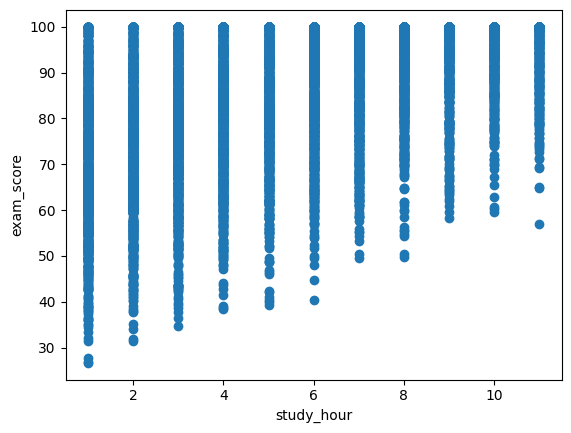

In [36]:
import matplotlib.pyplot as plt
plt.scatter(df.study_hours,df.exam_score)
plt.xlabel("study_hour")
plt.ylabel("exam_score")
plt.show()


In [37]:
from sklearn.model_selection import(
    train_test_split)
x = df[["study_hours", "attendance", "previous_score", "sleep_hours"]]
y = df['exam_score']
x_train, x_test, y_train, y_test = (
    train_test_split(x,y, test_size = 0.2, random_state = 42)
)

In [38]:
medians = x_train.median()
x_train = x_train.fillna(medians)
x_test = x_test.fillna(medians)

In [39]:
from sklearn.ensemble import(
    RandomForestRegressor
)
model = RandomForestRegressor(random_state=42)
model.fit(x_train,y_train)

RandomForestRegressor(random_state=42)

In [41]:
from sklearn.metrics import mean_absolute_error
predictions = model.predict(x_test)
mae = mean_absolute_error(y_test,predictions)
print("MAE:",round(mae,1))

MAE: 8.7


In [42]:
new_student = pd.DataFrame({
    "study_hours": [6],
    "attendance":[90],
    "previous_score": [75],
    "sleep_hours": [8],
})
score = model.predict(new_student)[0]
print("predicted score:",round(score))

predicted score: 99
